# 03. 特徴量エンジニアリング: 採用した13種類(16個)の特徴量の考え方とコード

**このノートブックの目的:** ベースライン(元の特徴量20個)に足す特徴量を、EDAの発見・事前確認・公開ノートブックなどから考え、1つずつ判定して選ぶ。

**使うもの:** `data/train.csv`・`data/test.csv`。ベースラインのスコアは 00_baseline、着想のもとになったグラフは 01_EDA。

**結論:** 約180個の候補(不採用169個)から13種類(16個)を採用し、LightGBMのOOF AUCは0.95846→0.96046になった。最大の改善はFlight Distanceの値ごとの満足率(+0.00136)。

- 採用した特徴量を3つの作り方(① 条件で絞る / ② 似た乗客で数える・平均する / ③ モデルで予想する)に分け、考えた順に並べる。
- 1つの特徴量ごとに **【仮説】→【確認】(その場で集計)→【結果】→【施策】(特徴量を作るコード)** の順に書く。改善幅は後半の「採否の判定」の基準で測った値。
- 試したが採用しなかった候補は、後半の「不採用にした特徴量」の表にまとめた。
- ここのコードは説明のために書き下したもの。モデルの学習に使う同じ処理は `src/features.py` にあり、**最後のセルで両方が全行で同じ特徴量を作ることを照合する**(食い違えばエラーで止まる)。

## 準備

- ライブラリと、複数のノートブックで使う共通処理(`src/`の自分で書いたPythonファイル)を読み込む。`sys.path.insert(0, "../src")` で `src/` を探す場所に加え、`import features`・`import modeling` で中の関数や設定を使えるようにする。
  - `src/features.py`(データと特徴量)
    - データの読み込み(`load_train_and_test`)と、元の特徴量の一覧(21個 `ORIGINAL_FEATURES_BY_UNIVARIATE_AUC`、ベースラインの20個 `BASE_FEATURES`)
    - 採用した16個の特徴量を作る関数(`comfort_business_travel` など。一覧は `FEATURE_BUILDERS`)
    - 特徴量の表を作る関数(`build_train_and_test_tables`: 元の特徴量と採用した特徴量を並べ、カテゴリ変数をcategory型にする)
    - 値ごとの満足率を、foldの学習側だけで計算する関数(`target_encode_in_folds`)
  - `src/modeling.py`(学習と評価)
    - 交差検証(`cross_validate_lightgbm`・`cross_validate_xgboost`: 5分割で学習し、OOFとtestの予測を返す)
    - ハイパラ(既定の値と、05で採用した `TUNED_LIGHTGBM_PARAMS`・`TUNED_XGBOOST_PARAMS`)と、Optunaでの探索
    - 予測どうしの順位相関の表(`rank_correlation_table`)
    - スタッキング(2段目のロジスティック回帰・浅いLightGBM、最終の提出用の予測)
- train・testを読み込み、目的変数 `satisfaction` を0/1の配列 `y` にする。
- `satisfaction_rate`: グループごとの満足率と人数を出す確認用の関数。各特徴量の【確認】で使う。

In [1]:
import sys

sys.path.insert(0, "../src")  # 共通処理(features.py・modeling.py)を読み込む
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

import features
import modeling

plt.rcParams["font.family"] = "Meiryo"
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
y = train["satisfaction"].astype(int).values
print(f"train {len(train):,}行・test {len(test):,}行、満足率 {y.mean():.3f}")


def satisfaction_rate(by):
    """グループごとの満足率と人数の表(確認用)。"""
    return train.assign(_y=y).groupby(by, observed=True)["_y"].agg(満足率="mean", 人数="size").round(3)

train 699,635行・test 299,844行、満足率 0.444


## ① 条件で絞る(ゲート特徴量)

点数が効く客層だけに値を持たせ、ほかの客は空欄(欠損)にする。木のモデルは「空欄かどうか」でも分岐できるので、「この客層ではこの点数が効く」という関係を1列で渡せる。

### 1. 出張客の快適さ(`comfort_business_travel`)

**【仮説】** 私用客は、Seat comfortやInflight entertainmentが快適でも満足しないのでは?(EDA 3節: 私用旅行はClassに関係なく満足率9.5〜11.2%)

**【確認】** 快適さ(Seat comfort・Leg room service・Inflight entertainmentの点数の平均。0点は「評価なし」の可能性があるので除く)を四捨五入し、Type of Travelごとの満足率を見る。

In [2]:
COMFORT_RATINGS = ["Seat comfort", "Leg room service", "Inflight entertainment"]


def comfort(df):
    return df[COMFORT_RATINGS].replace(0, np.nan).mean(axis=1)


satisfaction_rate(["Type of Travel", comfort(train).round()])["満足率"].unstack()

,1.0,2.0,3.0,4.0,5.0
Type of Travel,,,,,
Business travel,0.125,0.147,0.324,0.750,0.887
Personal Travel,0.099,0.093,0.091,0.103,0.119


**【結果】** 出張客は、快適さが4点で満足率75.0%、5点で88.7%と大きく上がる(3点以下は12.5〜32.4%)。私用客は、どの点数でも9.1〜11.9%でほぼ横ばい。快適さは出張客にだけ効く。

**【施策】** 快適さを出張客だけに持たせ、私用客は空欄にする。改善幅 **+0.000063**(3seed平均)。ゲートなしの快適さ(全員に値を持たせる版)は効かなかったので、効果はゲートによるもの。

In [3]:
def comfort_business_travel(df):
    return pd.DataFrame({"comfort_business_travel": comfort(df).where(df["Type of Travel"] == "Business travel")})

### 2. 常連かつ出張客の快適さ(`comfort_loyal_business_travel`)

**【仮説】** 出張客の中でも、常連でない客(初めて・たまにしか乗らない客)には快適さが効かないのでは?(EDA 4節)

**【確認】** 出張客に絞り、Customer Type×快適さの満足率を見る。

In [4]:
business = train["Type of Travel"] == "Business travel"
train[business].assign(_y=y[business], comfort=comfort(train[business]).round()).pivot_table(
    index="Customer Type", columns="comfort", values="_y", aggfunc="mean").round(3)

comfort,1.0,2.0,3.0,4.0,5.0
Customer Type,,,,,
Loyal Customer,0.081,0.116,0.388,0.873,0.956
disloyal Customer,0.155,0.187,0.205,0.209,0.228


**【結果】** 常連の出張客は、快適さが4点で87.3%、5点で95.6%まで上がる。常連でない出張客は、1点15.5%から5点22.8%までしか上がらない。快適さが効くのは常連の出張客に限られる。

**【施策】** 快適さを常連の出張客だけに持たせる。改善幅 **+0.000070**(3seed平均)。SHAP(予測への寄与)で全特徴量の1位になった。

In [5]:
def comfort_loyal_business_travel(df):
    mask = (df["Type of Travel"] == "Business travel") & (df["Customer Type"] == "Loyal Customer")
    return pd.DataFrame({"comfort_loyal_business_travel": comfort(df).where(mask)})

### 3. 出張客のOn-board service(`onboard_service_business_travel`)

**【仮説】** 快適さ以外の評価項目でも、出張客にだけ効くものがあるのでは?

**【確認】** On-board serviceの点数だけで満足/不満を並べ分けたときのAUC(0.5=当てずっぽう、1=完璧)を、出張客・私用客で比べる。

In [6]:
personal = ~business
pd.Series({"出張客": roc_auc_score(y[business], train.loc[business, "On-board service"]),
           "私用客": roc_auc_score(y[personal], train.loc[personal, "On-board service"])}, name="機内サービスの単変量AUC").round(3)

出張客    0.759
私用客    0.509
Name: 機内サービスの単変量AUC, dtype: float64

**【結果】** 単変量AUCは、出張客0.759、私用客0.509(ほぼ当てずっぽう)。On-board serviceの点数も、出張客にだけ効く。

**【施策】** On-board serviceの点数を出張客だけに持たせる。改善幅 **+0.000045**(3seed平均)。

In [7]:
def onboard_service_business_travel(df):
    return pd.DataFrame({"onboard_service_business_travel": df["On-board service"].where(df["Type of Travel"] == "Business travel")})

## ② 似た乗客で数える・平均する

Flight Distanceは値の種類が多く(3,474種類)、同じFlight Distance=同じ路線と考えられる。同じ路線・同じ客層の乗客をまとめて、満足率・人数・評価の平均などを特徴量にする。

満足率(Target Encoding)は答えを使うので、**自分の答えが混ざらないように**作る(下の`target_encode_in_folds`)。人数が少ない値は、全体の満足率に寄せて極端な値を防ぐ(強さm=3)。

In [8]:
def target_encode(key_fit, y_fit, key_apply, m=3):
    """key_fitの値ごとの満足率を、人数が少ないほど全体の満足率に寄せて計算し、key_applyに当てはめる。"""
    prior = y_fit.mean()
    stats = pd.DataFrame({"key": key_fit, "y": y_fit}).groupby("key")["y"].agg(["sum", "count"])
    return pd.Series(key_apply).map((stats["sum"] + m * prior) / (stats["count"] + m)).fillna(prior).values


def target_encode_in_folds(key_fit, y_fit, key_others, seed, m=3):
    """学習用の行は、その中でさらに5分割し、自分を含まない4つで計算した満足率を入れる。
    検証用・testの行(key_others)には、学習用の行全体の満足率を入れる。"""
    encoded = np.zeros(len(key_fit))
    for inner_fit, inner_apply in StratifiedKFold(5, shuffle=True, random_state=seed).split(key_fit, y_fit):
        encoded[inner_apply] = target_encode(key_fit[inner_fit], y_fit[inner_fit], key_fit[inner_apply], m)
    return encoded, [target_encode(key_fit, y_fit, key, m) for key in key_others]


def oof_target_encoding_auc(key):
    """確認用: 5分割の外側で満足率を当てはめ、その満足率だけで満足/不満を並べ分けたときのAUC。"""
    oof = np.zeros(len(key))
    for fit, apply in StratifiedKFold(5, shuffle=True, random_state=42).split(key, y):
        oof[apply] = target_encode(key[fit], y[fit], key[apply])
    return roc_auc_score(y, oof)

### 4. Flight Distanceの値ごとの満足率(`distance_satisfaction_rate`)

**【仮説】** Flight Distanceは「長いほど満足」というまっすぐな関係ではなく、値ごと(路線ごと)に満足率のクセがあるのでは?

**【確認】** Flight Distanceの値の種類の数と、「Flight Distanceそのもの」と「Flight Distanceの値ごとの満足率」それぞれの単変量AUCを比べる。

In [9]:
distance = train["Flight Distance"].values
pd.Series({"値の種類": train["Flight Distance"].nunique(),
           "Flight DistanceそのもののAUC": round(roc_auc_score(y, distance), 3),
           "値ごとの満足率のAUC": round(oof_target_encoding_auc(distance), 3)})

値の種類                       3474.000
Flight DistanceそのもののAUC       0.696
値ごとの満足率のAUC                   0.743
dtype: float64

**【結果】** Flight Distanceの値は3,474種類。Flight DistanceそのもののAUC 0.696に対し、値ごとの満足率は0.743と高い。Flight Distanceの大小より、値(路線)ごとのクセの方が満足度をよく表す。

**【施策】** 特徴量の作成ではFlight Distanceの値(キー)だけを置き、学習のfoldごとに`target_encode_in_folds`で満足率に置き換える。改善幅 **+0.00136**(1seed。特徴量エンジニアリングで最大の改善。Public LBは+0.00126)。

In [10]:
def distance_satisfaction_rate(df):
    return pd.DataFrame({"distance_satisfaction_rate": df["Flight Distance"]})  # 満足率への置き換えは学習ループの中で行う

### 5. Flight Distance×Classの満足率(`distance_class_satisfaction_rate`)

**【仮説】** 同じ路線でも、ビジネス席とエコノミー席では満足率が違うのでは?(EDA 3節: Flight Distanceの効き方は客層で違う)

**【確認】** 「Flight Distanceだけ」と「Flight Distance×Class」の満足率の単変量AUCを比べる。

In [11]:
distance_class = (train["Flight Distance"].astype(str) + "|" + train["Class"]).values
pd.Series({"Flight Distanceだけの満足率のAUC": round(oof_target_encoding_auc(distance), 3),
           "Flight Distance×Classの満足率のAUC": round(oof_target_encoding_auc(distance_class), 3)})

Flight Distanceだけの満足率のAUC        0.743
Flight Distance×Classの満足率のAUC    0.839
dtype: float64

**【結果】** Flight Distanceだけの満足率のAUC 0.743に対し、Flight Distance×Classでは0.839まで上がる。同じ路線でもClassで満足率が大きく違う。

**【施策】** Flight DistanceとClassをつないだキー(例: `"1235|Business"`)を置き、学習ループの中で満足率に置き換える。改善幅 **+0.000060**(3seed平均)。

In [12]:
def distance_class_satisfaction_rate(df):
    key = df[["Flight Distance", "Class"]].fillna(-1).astype(str).agg("|".join, axis=1)
    return pd.DataFrame({"distance_class_satisfaction_rate": key})

### 6. Flight Distance×Type of Travelの出現回数(`distance_travel_type_count`)

**【仮説】** 出張客の多い路線(ビジネス路線)かどうかは、満足率と関係するのでは?(2つ前のコンペで、値の出現回数を足すと効いた経験から。候補は13個試した)

**【確認】** 同じFlight Distance・同じType of Travelの乗客がtrain+testに何人いるかを数え、人数を5つの区間に分けて満足率を見る。

In [13]:
def count_in_train_and_test(df, cols):
    keys = [pd.read_csv(f, usecols=cols)[cols].fillna(-1).astype(str).agg("|".join, axis=1) for f in ("../data/train.csv", "../data/test.csv")]
    counts = pd.concat(keys).value_counts()
    return df[cols].fillna(-1).astype(str).agg("|".join, axis=1).map(counts).values


dist_travel_count = count_in_train_and_test(train, ["Flight Distance", "Type of Travel"])
satisfaction_rate(["Type of Travel", pd.qcut(dist_travel_count, 5, duplicates="drop")])["満足率"].unstack()

,"(0.999, 190.0]","(190.0, 537.0]","(537.0, 1202.0]","(1202.0, 2340.0]","(2340.0, 7170.0]"
Type of Travel,,,,,
Business travel,0.705,0.613,0.542,0.545,0.503
Personal Travel,0.112,0.099,0.101,0.089,0.089


**【結果】** 出張客は、同じ路線・同じ目的の乗客が少ない(190人以下)ほど満足率が高く(70.5%)、多い(2,340人超)と50.3%まで下がる。私用客は8.9〜11.2%でほぼ横ばい。出張客の多い大きな路線ほど満足しにくい。

**【施策】** 人数をそのまま特徴量にする(答えは使わないので、train+testで数えてよい)。改善幅 **+0.000057**(3seed平均)。試した13個のうち、効いたのはFlight Distance×Type of Travelの出現回数だけ。

In [14]:
def distance_travel_type_count(df):
    return pd.DataFrame({"distance_travel_type_count": count_in_train_and_test(df, ["Flight Distance", "Type of Travel"])}, index=df.index)

In [15]:
def route_stat(df, col, stat):
    """同じFlight Distance(=同じ路線とみなす)の乗客の、colの平均や標準偏差(train+testで計算。答えは使わない)。"""
    both = pd.concat([pd.read_csv(f, usecols=["Flight Distance", col]) for f in ("../data/train.csv", "../data/test.csv")])
    return df["Flight Distance"].map(both.groupby("Flight Distance")[col].agg(stat)).values

### 7. Leg room serviceの路線平均(`route_mean_legroom`)

**【仮説】** 路線ごとに機材(座席の間隔)が違い、Leg room serviceの評判がその路線の満足度を表すのでは?(Discussion: Flight Distanceを路線IDとみなす)

**【確認】** 路線ごとのLeg room serviceの点数の平均を5つの区間に分け、満足率を見る。

In [16]:
satisfaction_rate(pd.qcut(route_stat(train, "Leg room service", "mean"), 5))

,満足率,人数
"(-0.001, 3.238]",0.304,139985
"(3.238, 3.304]",0.284,140212
"(3.304, 3.407]",0.316,140509
"(3.407, 3.759]",0.515,140212
"(3.759, 5.0]",0.802,138717


**【結果】** Leg room serviceの路線平均が上位20%(3.76点超)の路線は満足率80.2%。下位60%の路線は28.4〜31.6%。路線ごとのLeg room serviceの評判で満足率が大きく変わる。

**【施策】** 路線平均をそのまま特徴量にする。改善幅 **+0.000061**(3seed平均)。

In [17]:
def route_mean_legroom(df):
    return pd.DataFrame({"route_mean_legroom": route_stat(df, "Leg room service", "mean")}, index=df.index)

### 8. Inflight wifi serviceの路線標準偏差(`route_std_wifi`)

**【仮説】** Inflight wifi serviceの評価が0点(使っていない)と5点に割れる路線は、客層が混ざった路線なのでは?(公開ノートブックの「路線プロファイル」から)

**【確認】** 路線ごとのInflight wifi serviceの点数の標準偏差(ばらつき)を5つの区間に分け、満足率を見る。

In [18]:
satisfaction_rate(pd.qcut(route_stat(train, "Inflight wifi service", "std"), 5))

,満足率,人数
"(-0.001, 1.164]",0.331,140131
"(1.164, 1.211]",0.326,140158
"(1.211, 1.258]",0.387,139848
"(1.258, 1.332]",0.493,141689
"(1.332, 2.887]",0.684,137723


**【結果】** Inflight wifi serviceのばらつきが大きい路線(上位20%)は満足率68.4%、小さい路線(下位40%)は32.6〜33.1%。評価が割れる路線ほど満足率が高い。

**【施策】** 路線の標準偏差をそのまま特徴量にする。改善幅 **+0.000048**(3seed平均)。

In [19]:
def route_std_wifi(df):
    return pd.DataFrame({"route_std_wifi": route_stat(df, "Inflight wifi service", "std")}, index=df.index)

### 9. 客層グループ内の偏差(`group_deviation`、4個)

**【仮説】** AgeやFlight Distanceは、客層によって平均が大きく違う(例: エコノミー×出張では、常連でない客は平均26.4歳、常連は43.5歳)。同じ36歳でも、前者の客層では年上、後者では若い。同じ客層の中で「平均より上か下か」が効くのでは?(公開ノートブックの48個の特徴量を、平均との差だけの4個に絞った)

**【確認】** Class×Type of Travel×Customer Typeの12グループのうち人数の多い7グループで、Ageがグループ平均よりどれだけ上か下かで4つに分け、満足率を比べる。

In [20]:
GROUP_KEYS = ["Class", "Type of Travel", "Customer Type"]
GROUP_COLS = {"age": "Age", "flight_distance": "Flight Distance", "departure_delay": "Departure Delay in Minutes", "arrival_delay": "Arrival Delay in Minutes"}


def deviation_from_group_mean(df, col):
    both = pd.concat([pd.read_csv(f, usecols=GROUP_KEYS + [col]) for f in ("../data/train.csv", "../data/test.csv")])
    group_mean = both.groupby(GROUP_KEYS)[col].mean().rename("group_mean")
    return df[col].values - df[GROUP_KEYS].merge(group_mean, left_on=GROUP_KEYS, right_index=True, how="left")["group_mean"].values


group = train[GROUP_KEYS].agg(" × ".join, axis=1)
large_group = group.where(group.map(group.value_counts()) > 10000)  # 人数の少ないグループは満足率が揺れるので除く
age_dev = pd.Series(deviation_from_group_mean(train, "Age"), index=train.index)
age_dev_bin = pd.cut(age_dev, [-np.inf, -10, 0, 10, np.inf], labels=["10歳以上若い", "0〜10歳若い", "0〜10歳上", "10歳以上上"])
satisfaction_rate([large_group, age_dev_bin])["満足率"].unstack()

,10歳以上若い,0〜10歳若い,0〜10歳上,10歳以上上
Business × Business travel × Loyal Customer,0.670,0.794,0.844,0.826
Business × Business travel × disloyal Customer,0.874,0.429,0.140,0.315
Eco Plus × Business travel × Loyal Customer,0.366,0.408,0.420,0.375
Eco Plus × Personal Travel × Loyal Customer,0.096,0.095,0.108,0.089
Eco × Business travel × Loyal Customer,0.373,0.468,0.403,0.350
Eco × Business travel × disloyal Customer,0.115,0.172,0.048,0.060
Eco × Personal Travel × Loyal Customer,0.104,0.096,0.097,0.090


**【結果】** 客層の中でのAgeの位置で、満足率は大きく変わる。ビジネス×出張×常連でないのグループ(平均31.9歳)では、平均より10歳以上若い客の満足率は87.4%、平均より0〜10歳上の客は14.0%。ただし向きはグループで違い、ビジネス×出張×常連では若い客の方が満足率が低い(10歳以上若い客67.0%、平均より上の客82.6〜84.4%)。

なお、遅延のグループ平均はどのグループも1分前後(0.8〜1.6分)で差がなく、遅延の差は元の遅延とほぼ同じ情報になる。

**【施策】** Age・Flight Distance・Departure Delay in Minutes・Arrival Delay in Minutesの4つについて、グループ平均との差を特徴量にする。改善幅 **+0.0000375**(3seed平均)。

In [21]:
def group_deviation(df):
    return pd.DataFrame({f"group_deviation_{short}": deviation_from_group_mean(df, col) for short, col in GROUP_COLS.items()}, index=df.index)

### エンコーディングの比較

値の渡し方(エンコーディング)は、ベースラインのあとに1つずつ比べて決めた。4(値ごとの満足率)と6(出現回数)は、この比較から採用した。

| 比べたもの | 結果 | 採否 |
|---|---|---|
| Flight Distance: 値そのまま vs 値ごとの満足率(Target Encoding) | 値ごとの満足率で+0.00136(1seed。特徴量エンジニアリングで最大の改善) | 採用 |
| 値ごとの満足率の強さ(人数の少ない値を全体の満足率に寄せる強さm=1・3・5・10・20・50) | m=3が最良(OOF 0.959983)。m=50は0.959752に下がった | m=3を採用 |
| 値の出現回数(Frequency Encoding)の13候補 | Flight Distance×Type of Travelだけが効いた(+0.000057、3seed平均) | 1個だけ採用 |
| Flight Distanceをcategory型(3,474種類)で渡す | −0.00121 | 不採用 |
| カテゴリ変数4つ(Gender・Customer Type・Type of Travel・Class)のOne-Hot | 試していない(値が2〜3種類しかなく、category型で渡したときと木の分け方がほぼ同じになるため) | — |

## ③ モデルで予想する

### 10. サービス評価の期待値(`expected_online_boarding`・`expected_legroom`・`expected_checkin`・`expected_time_convenient`)

**【仮説】** 同じ「4点」でも、ほかの項目にも高い点を付けている人の4点と、ほかは低い人の4点では意味が違うのでは?「ほかの項目への答え方から見て、この人ならこの項目に何点を付けそうか」(期待値)を特徴量にすれば、その違いを渡せる(公開ノートブックのアイデア)。

**【施策】** ほかの元の特徴量から、その項目の点数をLightGBMで予想する(`features.make_expected_rating`。5分割して、予想する行自身は学習に使わない。満足かどうかの答えも使わない)。1項目あたり数分かかるので、作った期待値は `data/` に保存し、次からは読み込む。

**【確認】** Online boardingが4点の人だけに絞り、期待値の高さで5つに分けて満足率を見る。

In [22]:
n_train = len(train)
train_and_test = pd.concat([train, test], ignore_index=True)
for name, rating_column in features.EXPECTED_RATINGS.items():  # 採用した4項目
    path = features.expected_rating_path(name)
    if not path.exists():
        np.save(path, features.make_expected_rating(rating_column))
    expected = np.load(path)
    print(f"{name}: 実際の点数との相関 {np.corrcoef(expected, train_and_test[rating_column])[0, 1]:.3f}")


def expected_rating(df, name):
    expected = np.load(features.expected_rating_path(name))  # train+testの順に保存されている
    return expected[:n_train] if len(df) == n_train else expected[n_train:]


score4 = (train["Online boarding"] == 4).values
expected_boarding = expected_rating(train, "expected_online_boarding")
pd.DataFrame({"期待値": expected_boarding[score4], "_y": y[score4]}).groupby(
    pd.qcut(expected_boarding[score4], 5), observed=True)["_y"].agg(満足率="mean", 人数="size").round(3)

expected_online_boarding: 実際の点数との相関 0.917
expected_legroom: 実際の点数との相関 0.622
expected_checkin: 実際の点数との相関 0.522
expected_time_convenient: 実際の点数との相関 0.865


,満足率,人数
"(-0.001, 3.953]",0.273,42190
"(3.953, 4.002]",0.433,42190
"(4.002, 4.341]",0.741,42190
"(4.341, 4.454]",0.825,42190
"(4.454, 4.983]",0.936,42190


**【結果】** 同じ4点でも、期待値が低い人(ほかの項目の点数も低い人)は満足率27.3%、期待値が高い人は93.6%。点数そのものが同じでも、期待値によって満足率が大きく違う。

サービス評価13項目を1つずつ判定し、4項目(Online boarding・Leg room service・Checkin service・Departure/Arrival time convenient)を採用した。改善幅は各 **+0.000037〜+0.000088**。

In [23]:
def expected_rating_features(df):
    return pd.DataFrame({name: expected_rating(df, name) for name in features.EXPECTED_RATINGS}, index=df.index)

## 採否の判定

**目的:** 候補を足したときの小さな伸び(+0.00005前後)が、たまたまでないかを見分ける。

**判定の仕方(LightGBM、既定のハイパラ):**
- 今の土台(元の特徴量20個+それまでに採用した特徴量)と「土台+候補1つ」を、同じ5分割で学習してOOF AUCを比べる。
- 最初の2日は、seed 42の1回で「OOFが上がれば採用」としていた。ところが、1seedで採用したFlight Distance×Type of Travelの出現回数(+0.00011)を、fold分割の乱数(seed)を変えて測り直すと、+0.000107・−0.000026・+0.000090と揺れ、seedによっては悪化した。
- そこで基準を決めた: **3つのseed(42・0・1)で測り、差の平均が+0.00003以上、かつ2seed以上で改善なら採用**。+0.00003は、1seedの差の揺れ(約0.00005)を√3で割った、3seed平均の揺れの大きさ。それまで1seedで採用していた8つも、この基準で確かめ直した。

**反省:** この基準は緩く、効果がゼロの候補でも約16%が通る。基準にわずかに届かなかった5つ(3seed平均+0.000001〜+0.000026)をまとめて入れても、採用に使っていないseedでは+0.000005とほぼ効かなかった。次のコンペからは、基準を揺れの2つ分に厳しくした。

### 採用した特徴量(13種類・16個)

| 特徴量 | 作った理由(着想のもと) | 改善幅(3seed平均) |
|---|---|---|
| `comfort_business_travel` 出張客の快適さ | 私用客は快適さに関係なく満足率約10%(EDA 3節) | +0.000063 |
| `comfort_loyal_business_travel` 常連かつ出張客の快適さ | 常連でない客には快適さが効かない(EDA 4節) | +0.000070 |
| `onboard_service_business_travel` 出張客のOn-board service | 単変量AUC 出張客0.759・私用客0.509(EDA 3・4節) | +0.000045 |
| `distance_satisfaction_rate` Flight Distanceの値ごとの満足率 | 値ごとの満足率の単変量AUC 0.743 > Flight Distanceそのもの0.696(事前確認) | +0.00136(1seed) |
| `distance_class_satisfaction_rate` Flight Distance×Classの満足率 | Flight Distanceの効き方は客層で違う(EDA 3節) | +0.000060 |
| `distance_travel_type_count` Flight Distance×Type of Travelの人数 | 人工データでは値の出現回数が効いた経験(2つ前のコンペ) | +0.000057 |
| `route_mean_legroom` Leg room serviceの路線平均 | Flight Distanceを路線IDとみなす見方(Discussion・公開ノートブック) | +0.000061 |
| `route_std_wifi` Inflight wifi serviceの路線標準偏差 | 路線ごとの評価のばらつき(公開ノートブック) | +0.000048 |
| `group_deviation`(4個) 客層グループ内の偏差 | 客層でAge・Flight Distanceの平均が大きく違う(公開ノートブック) | +0.0000375 |
| `expected_*`(4個) サービス評価の期待値 | 同じ点数でも、ほかの項目への答え方で意味が違う(公開ノートブック) | 各+0.000037〜+0.000088 |

### 不採用にした特徴量(169個、作り方でまとめた)

| 作り方 | 試した数 | 例 | 不採用の理由 |
|---|---|---|---|
| 0点の印・0点の個数 | 10 | 評価が0点かどうか(12項目)、0点・1点・5点の個数、路線の0点の割合 | 木は「評価が0.5以下」の1回の分岐で0点の人を切り出せる。0点の個数は1seedで+0.00001、3seedで基準に届かず |
| サービス評価のまとめ値 | 6 | 13項目の平均・最小・最大・標準偏差 | 木が元の13項目の分岐で同じ区別を作れる |
| ゲート特徴量(1項目ずつ・ほかの客層) | 26 | 出張客のCleanliness・Seat comfort、私用客のEase of Online booking、常連でない客のInflight wifi service | On-board service以外は、木がType of Travelとその項目の2回の分岐で作れる |
| 掛け算・割り算・遅延の組み合わせ | 13 | Flight Distance×快適さ、Flight Distance÷快適さ、遅延の差・比・和 | 効果なし |
| 値ごとの満足率(Target Encoding) | 16 | Age、遅延、評価2項目の組、Age×Class、Flight Distanceを10・100で丸めた値 | Flight Distance以外は値ごとのクセが小さく、伸びなかった |
| 値の出現回数 | 12 | Flight Distance、Age、遅延、Flight Distance×Class | 13個試して、効いたのはFlight Distance×Type of Travelだけ |
| 路線の平均・標準偏差・割合 | 39 | 15項目の路線平均、14項目の路線標準偏差、路線の出張客の割合 | 路線平均どうしは似ていて、1つ入れると残りは新しい情報になりにくい |
| サービス評価の期待値(ほかの項目) | 13 | On-board service・Inflight wifi service・Ease of Online bookingなどの期待値 | ほかの特徴量から点数をほぼ当てられ、期待値と実際の点数のずれが小さい |
| 客層グループ内の偏差(ほかの列) | 5 | Online boarding・Inflight wifi serviceの点数の偏差、標準偏差で割った偏差 | Age・Flight Distance・遅延の4個より伸びなかった |
| 2項目が同じ点数か | 4 | Inflight wifi serviceとDeparture/Arrival time convenientが同じ点数か | 効果なし |
| 数字の桁・トークン | 17 | Flight Distance・Age・遅延の1・10・100の位、GPT-2のトークン | 効果なし |
| このコンペのデータの元になった公開データ | 2 | 元データでの値ごとの満足率 | OOFは+0.00031だったが、Public LBが−0.00020だったので外した(終了後、Private LBでは+0.00025と効いていた) |
| 元の特徴量を外す・Gender・欠損の補完 | 6 | Gate location・遅延を外す、Genderを足す、Arrival Delay in Minutesの欠損を補完 | 外すと悪化、足しても補完しても効果なし |

## 採用した36個でLightGBMを学習する

**目的:** 採用した特徴量をすべて入れたときのスコアを、ベースラインと同じ分け方で確かめる。このOOFとtestの予測は、04_modelingでほかのモデルと比べるときに使う。

**検証方法:** 元の特徴量20個+作った16個=36個。ハイパラは既定のまま(調整は05)。値ごとの満足率は、foldごとに答えを見ない値へ置き換える。

In [24]:
X, X_test = features.build_train_and_test_tables(train, test)
print(f"特徴量 {X.shape[1]}個")
oof_default, test_default = modeling.cross_validate_lightgbm(X, y, X_test=X_test)
np.save(features.DATA_DIR / "oof_lightgbm_default.npy", oof_default)
np.save(features.DATA_DIR / "test_lightgbm_default.npy", test_default)
baseline = roc_auc_score(y, np.load(features.DATA_DIR / "oof_lightgbm_baseline.npy"))
print(f"OOF AUC: ベースライン {baseline:.6f} → 36個 {roc_auc_score(y, oof_default):.6f}")

特徴量 36個


fold0: AUC 0.960566 木766本 (49秒)


fold1: AUC 0.959283 木752本 (90秒)


fold2: AUC 0.961184 木861本 (136秒)


fold3: AUC 0.960654 木542本 (168秒)


fold4: AUC 0.960383 木557本 (200秒)


OOF AUC: ベースライン 0.958459 → 36個 0.960408


#### 結果と考察

- OOF AUCは0.95846→0.96046(+0.0020)(記録の値。このノートブックを再実行すると36個は0.960408になる。ライブラリの版など実行環境の違いによる差で、旧版のコードの再実行でも同じ値)。伸びの約7割は、Flight Distanceの値ごとの満足率(+0.00136)だった。
- 学習側のAUCはほぼ変わらず検証側だけが上がったので、答えの混入による見かけの改善ではないと考えられる。クセの原因は特定できていないが、このコンペのデータの元になった公開データの、路線ごとの満足率が残っている可能性がある。

## SHAPで効き方を確かめる

**目的:** 作った特徴量が、予測の中でどれくらい使われているかを見る。

**検証方法:** fold0のモデル(05で決めたハイパラ)で、検証側の3,000人について、特徴量ごとの予測への寄与(SHAP値、logitの単位)を計算し、絶対値の平均で並べる。

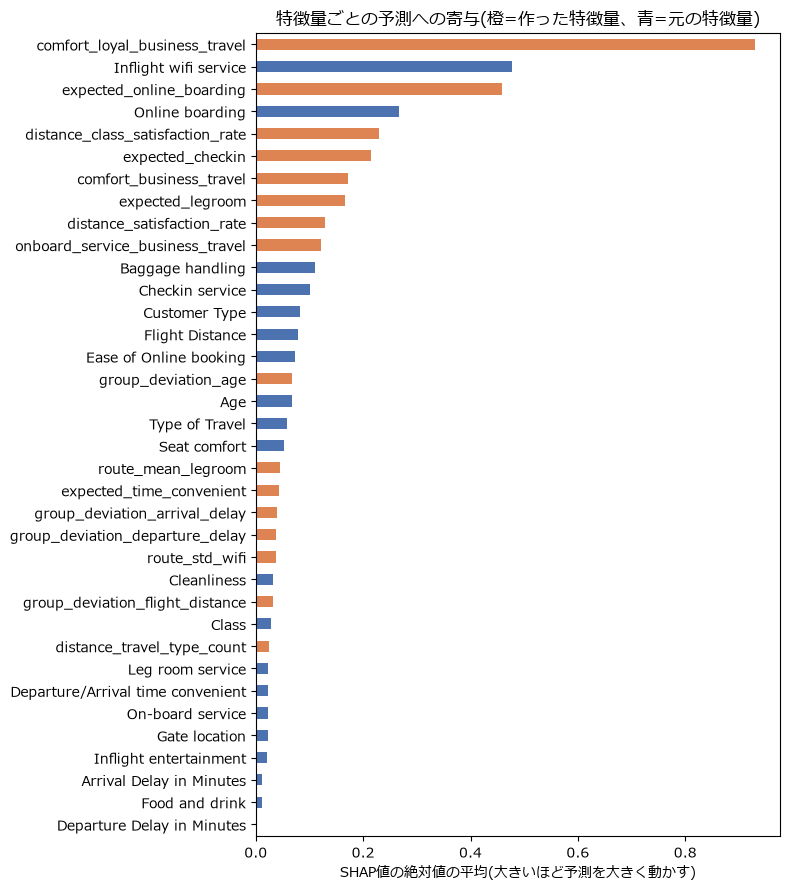

comfort_loyal_business_travel       0.930
Inflight wifi service               0.477
expected_online_boarding            0.459
Online boarding                     0.266
distance_class_satisfaction_rate    0.230
dtype: float64

In [25]:
fit_rows, valid_rows = next(StratifiedKFold(5, shuffle=True, random_state=42).split(X, y))
X_fit, (X_valid,) = features.target_encode_in_folds(X.iloc[fit_rows], y[fit_rows], [X.iloc[valid_rows]], seed=0)
model = lgb.LGBMClassifier(**modeling.TUNED_LIGHTGBM_PARAMS)
model.fit(X_fit, y[fit_rows], eval_X=(X_valid,), eval_y=(y[valid_rows],), eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
shap_rows = X_valid.sample(3000, random_state=0)
contributions = model.booster_.predict(shap_rows, pred_contrib=True)[:, :-1]  # 最後の列は全員共通の基準値
importance = pd.Series(np.abs(contributions).mean(axis=0), index=X.columns).sort_values()
created = [c for c in X.columns if c not in features.BASE_FEATURES]
fig, ax = plt.subplots(figsize=(8, 9))
importance.plot.barh(ax=ax, color=["#DD8452" if c in created else "#4C72B0" for c in importance.index])
ax.set_xlabel("SHAP値の絶対値の平均(大きいほど予測を大きく動かす)")
ax.set_title("特徴量ごとの予測への寄与(橙=作った特徴量、青=元の特徴量)")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).head(5).round(3)

#### 結果と考察

常連かつ出張客の快適さ(`comfort_loyal_business_travel`)が、元の特徴量も含めた全体の1位になった。「この客層だけ快適さが効く」という区別を1つの特徴量で渡せたため、木が多くの分岐を重ねずに使えたと考えられる。

## 学習に使うコードとの照合

ここで書いた関数と、学習に使う `src/features.py` の `FEATURE_BUILDERS` が、train・testの全行で同じ特徴量を作るかを確かめる。満足率の特徴量(4・5)は、キーと、foldごとに満足率へ置き換えた値の両方を比べる。

In [26]:
NOTEBOOK_BUILDERS = {name: globals()[name] for name in [
    "comfort_business_travel", "comfort_loyal_business_travel", "onboard_service_business_travel", "distance_satisfaction_rate",
    "distance_class_satisfaction_rate", "distance_travel_type_count", "route_mean_legroom", "route_std_wifi", "group_deviation"]}
assert set(NOTEBOOK_BUILDERS) | set(features.EXPECTED_RATINGS) == set(features.ADOPTED_FEATURES)
for df_name, df in (("train", train), ("test", test)):
    for name, build in NOTEBOOK_BUILDERS.items():
        pd.testing.assert_frame_equal(build(df), features.FEATURE_BUILDERS[name](df), check_names=False)
    module_expected = pd.concat([features.FEATURE_BUILDERS[name](df) for name in features.EXPECTED_RATINGS], axis=1)
    pd.testing.assert_frame_equal(expected_rating_features(df), module_expected)
    print(f"{df_name}: 13種類とも一致")

# 満足率への置き換え(fold0で比べる)
fit_rows, valid_rows = next(StratifiedKFold(5, shuffle=True, random_state=42).split(train, y))
keys = pd.concat([distance_satisfaction_rate(train), distance_class_satisfaction_rate(train)], axis=1)
module_fit, (module_valid,) = features.target_encode_in_folds(keys.iloc[fit_rows], y[fit_rows], [keys.iloc[valid_rows]], seed=0)
for name in keys.columns:
    notebook_fit, (notebook_valid,) = target_encode_in_folds(keys[name].values[fit_rows], y[fit_rows], [keys[name].values[valid_rows]], seed=0)
    assert np.array_equal(notebook_fit, module_fit[name].values) and np.array_equal(notebook_valid, module_valid[name].values), name
print("満足率への置き換えも一致")

train: 13種類とも一致


test: 13種類とも一致


満足率への置き換えも一致


## Summary

| 決めたこと | 値 |
|---|---|
| 採用した特徴量 | 13種類・16個(元の特徴量20個と合わせて36個) |
| 採否の基準 | 3seed(42・0・1)で差の平均+0.00003以上、かつ2seed以上で改善 |
| LightGBM(既定のハイパラ)のOOF AUC | 0.95846 → 0.96046 |

採用した特徴量を足し続けても、OOFの伸びが鈍った(最初の2日で+0.0017、次の4日で+0.00027)。Public LBも0.96002〜0.96007で4日間横ばいになったので、仕組みの違うモデルを足す(04_modeling)。